In [1]:
# Prerequisites
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.figsize"] = (12, 5)

In [2]:
from ponds import PONDS, GAUSS, SIGMOID
import matplotlib.pyplot as plt

## Generating a World Map of Synthetic Data

Using `PONDS` to generate a set of global, synthetic climate data is easy. First, we create an PONDS class object where we specify the number of grid points in latitudinal and longitudinal direction. We also specify how many time steps each time series consists. The PONDS object is initialised with `(lat_size x lon_size)` grid cells, each containing noisy data following a given background trend. <br>

To add one abrupt shift, we simply call the function `PONDS.add_shift()`. This function needs a `shape_method` and a `shift_method` argument which determine the shape of the blob in the grid and the type of abrupt shift in that spatial location. Additionally, the shift method can further be specified by additional `kwargs` arguments in form of a dictionary.

In [3]:
pd = PONDS(
    lat_size=20,
    lon_size=40,
    time_size=200,
    background_noise=0.01,
    background_trend=0.002,
)


pd.add_shift(random_seed=1, shape_method=GAUSS, shift_method=SIGMOID)

shift_dict = {
    "shift_steepness": 0.2,
    "shift_magnitude": 0.5,
}
pd.add_shift(
    random_seed=4,
    shape_method=GAUSS,
    shift_method=SIGMOID,
    kwargs=shift_dict,
)

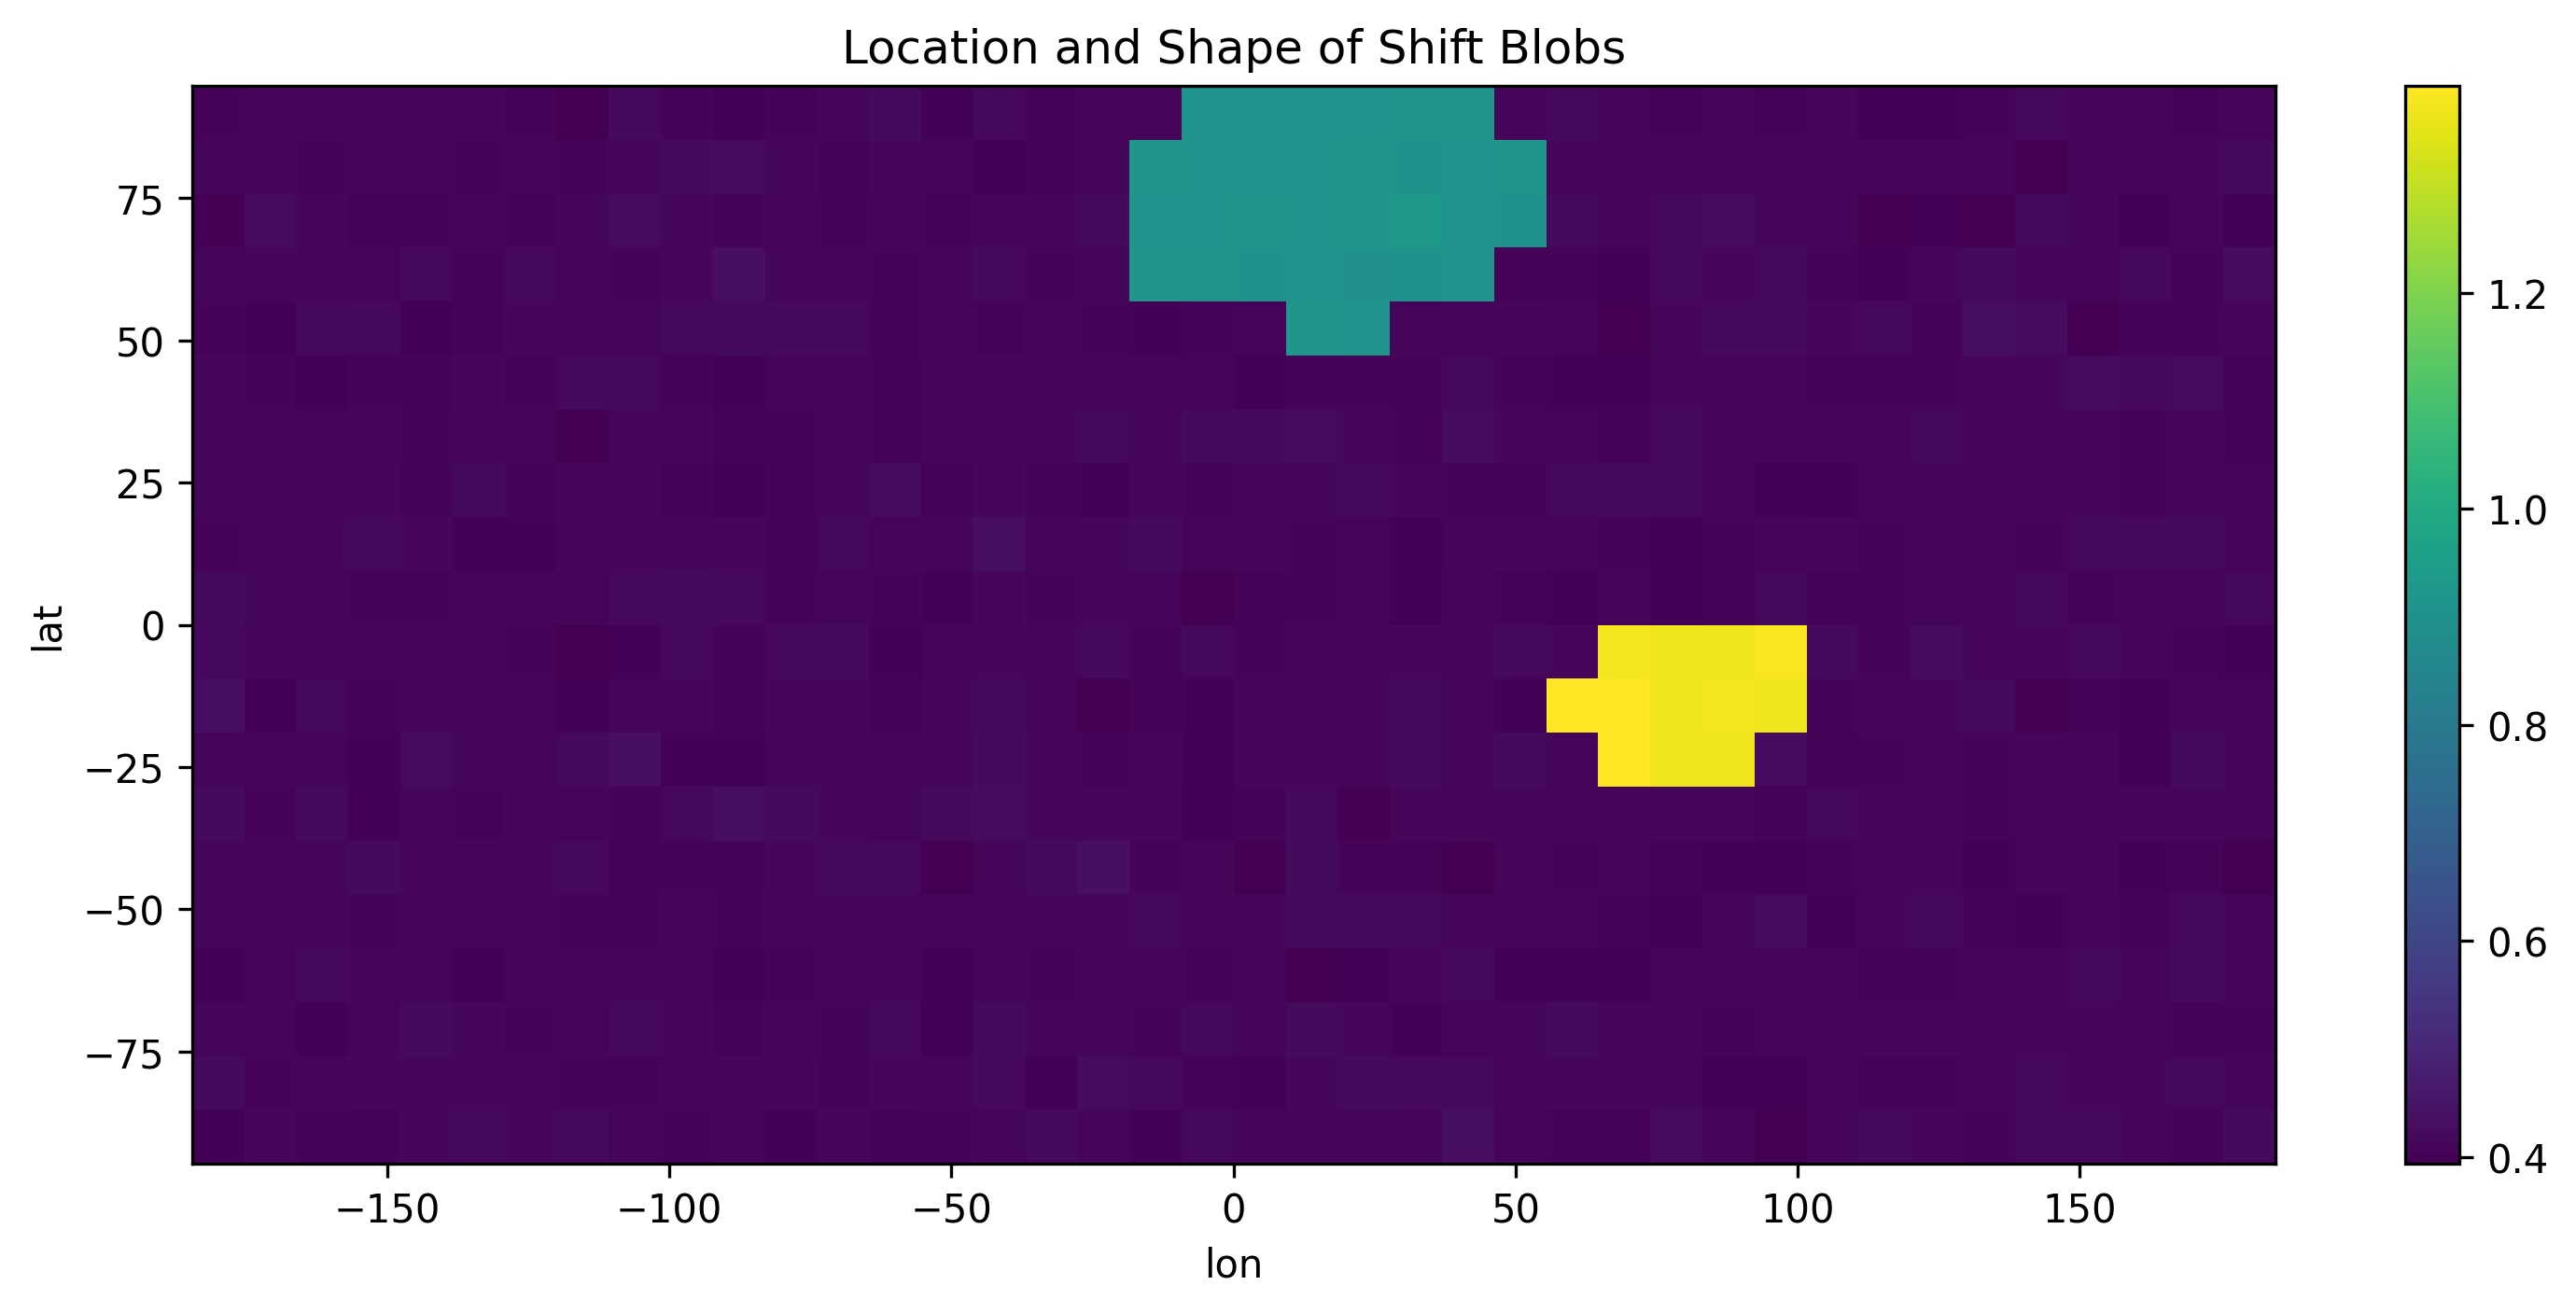

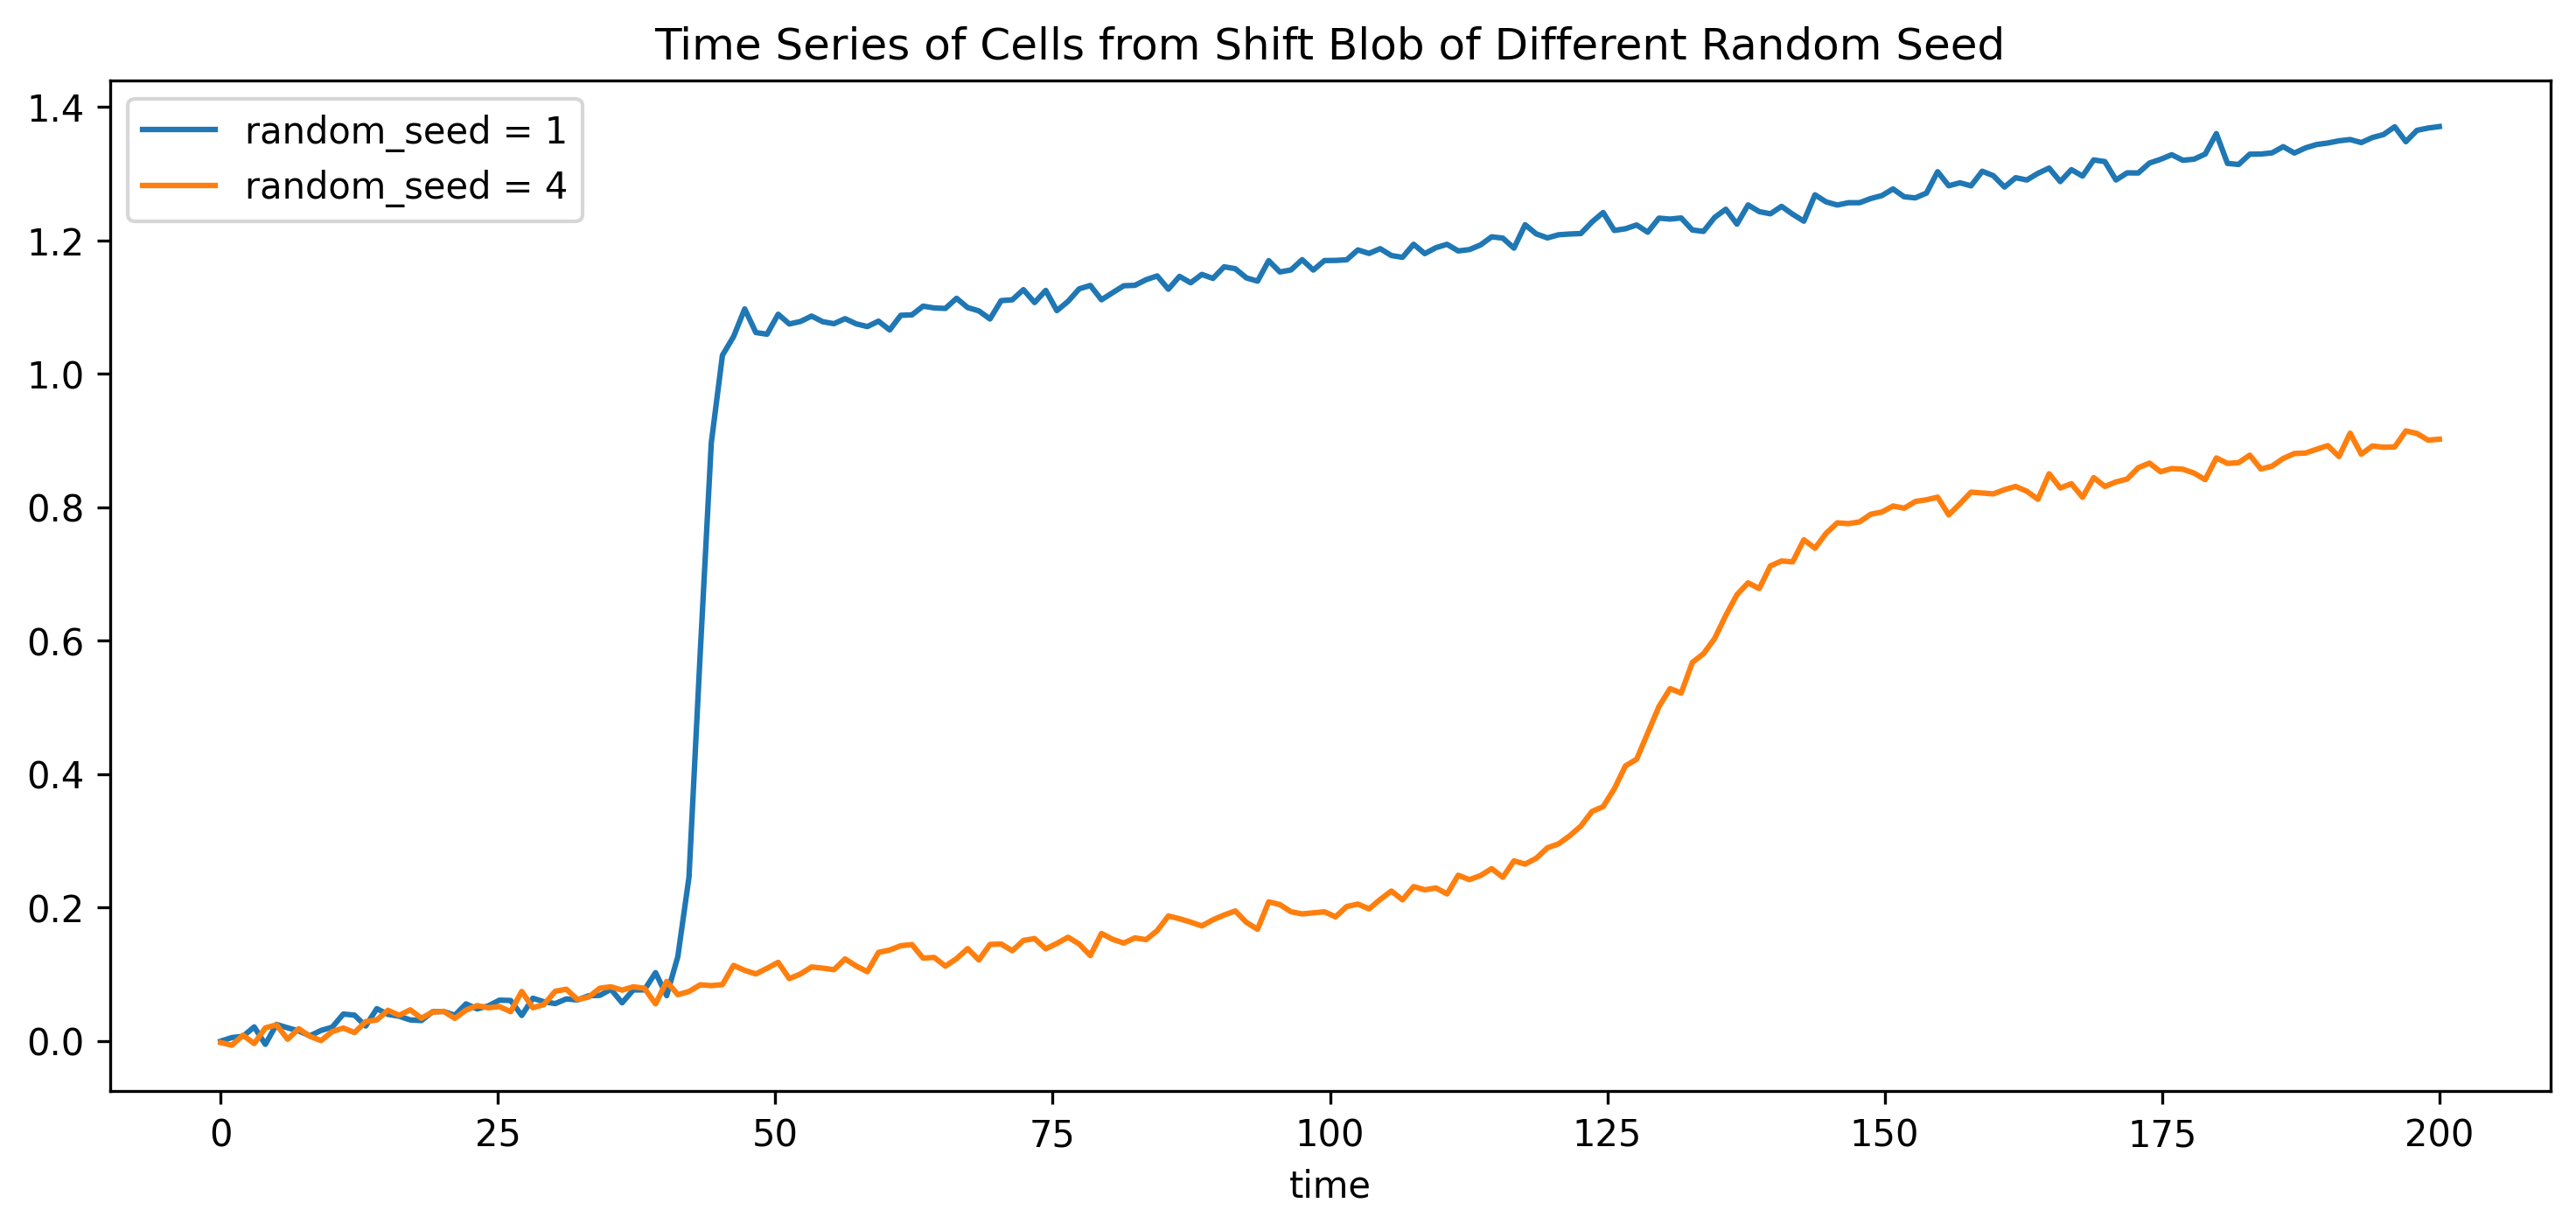

In [26]:
# look at generated time series data
pd.data.max(dim="time").plot()
plt.title("Location and Shape of Shift Blobs")
plt.show()

pd.data.isel(lat=8, lon=28).plot.line(x="time", label="random_seed = 1")
pd.data.isel(lat=17, lon=20).plot.line(x="time", label="random_seed = 4")
plt.legend()
plt.title("Time Series of Cells from Shift Blob of Different Random Seed")
plt.show()

## Using `PONDS` Data with `TOAD`

PONDS is developed in close prximity to TOAD and is therefore highly compatible with this abrupt shift detection package. We want to demonstrate here how a use case could look like.


In [27]:
from toad import TOAD
from toad.shifts_detection.methods import ASDETECT
from sklearn.cluster import HDBSCAN
from toad.visualisation.toad_plotter import PlotConfig

In [28]:
# from ipywidgets import interact
def plot(random_seed=0, n_shifts=1):
    pd = PONDS(
        lat_size=20,
        lon_size=30,
        time_size=200,
        random_seed=random_seed,
        background_noise=0.05,
    )

    for n in range(n_shifts):
        print(f">> Adding Shift {n + 1}/{n_shifts}...")
        pd.add_shift(shape_method=GAUSS, shift_method=SIGMOID)

    data_ds = pd.data.to_dataset(name="value")
    td = TOAD(data_ds)
    td.compute_shifts("value", ASDETECT())
    td.compute_clusters(
        "value",
        HDBSCAN(min_cluster_size=10),
        shifts_filter_func=lambda x: abs(x) > 0.9,
    )

    plt.rcParams["figure.dpi"] = 300

    plotter = td.plotter(
        PlotConfig(
            map_frame=False,
            grid_labels=False,
        )
    )

    plotter.cluster_overview(
        "value",
        range(10),
        cmap="tab10",
        timeseries_kwargs={},
        map_kwargs={"add_contour": False},
        figsize=(16, 5),
    )

    # Plot true shift locations
    fig, ax = plotter.map(figsize=(16, 4))
    pd.data.max(dim="time").plot(ax=ax, cmap="Blues")
    ax.set_title("True shift locations")

    # plot cluster timeseries
    fig, axs = plt.subplots(2, 1, figsize=(16, 4))
    plotter.cluster_timeseries("value", td.get_cluster_ids("value"), ax=axs[0])

    # plot data timeseries
    td.data.value.toad.to_timeseries().plot.line(
        x="time", add_legend=False, color="k", alpha=0.1, ax=axs[1]
    )
    axs[0].set_title(f"Cluster {td.get_cluster_ids('value')} timeseries")
    axs[1].set_title("All data timeseries")

>> Adding Shift 1/2...
>> Adding Shift 2/2...


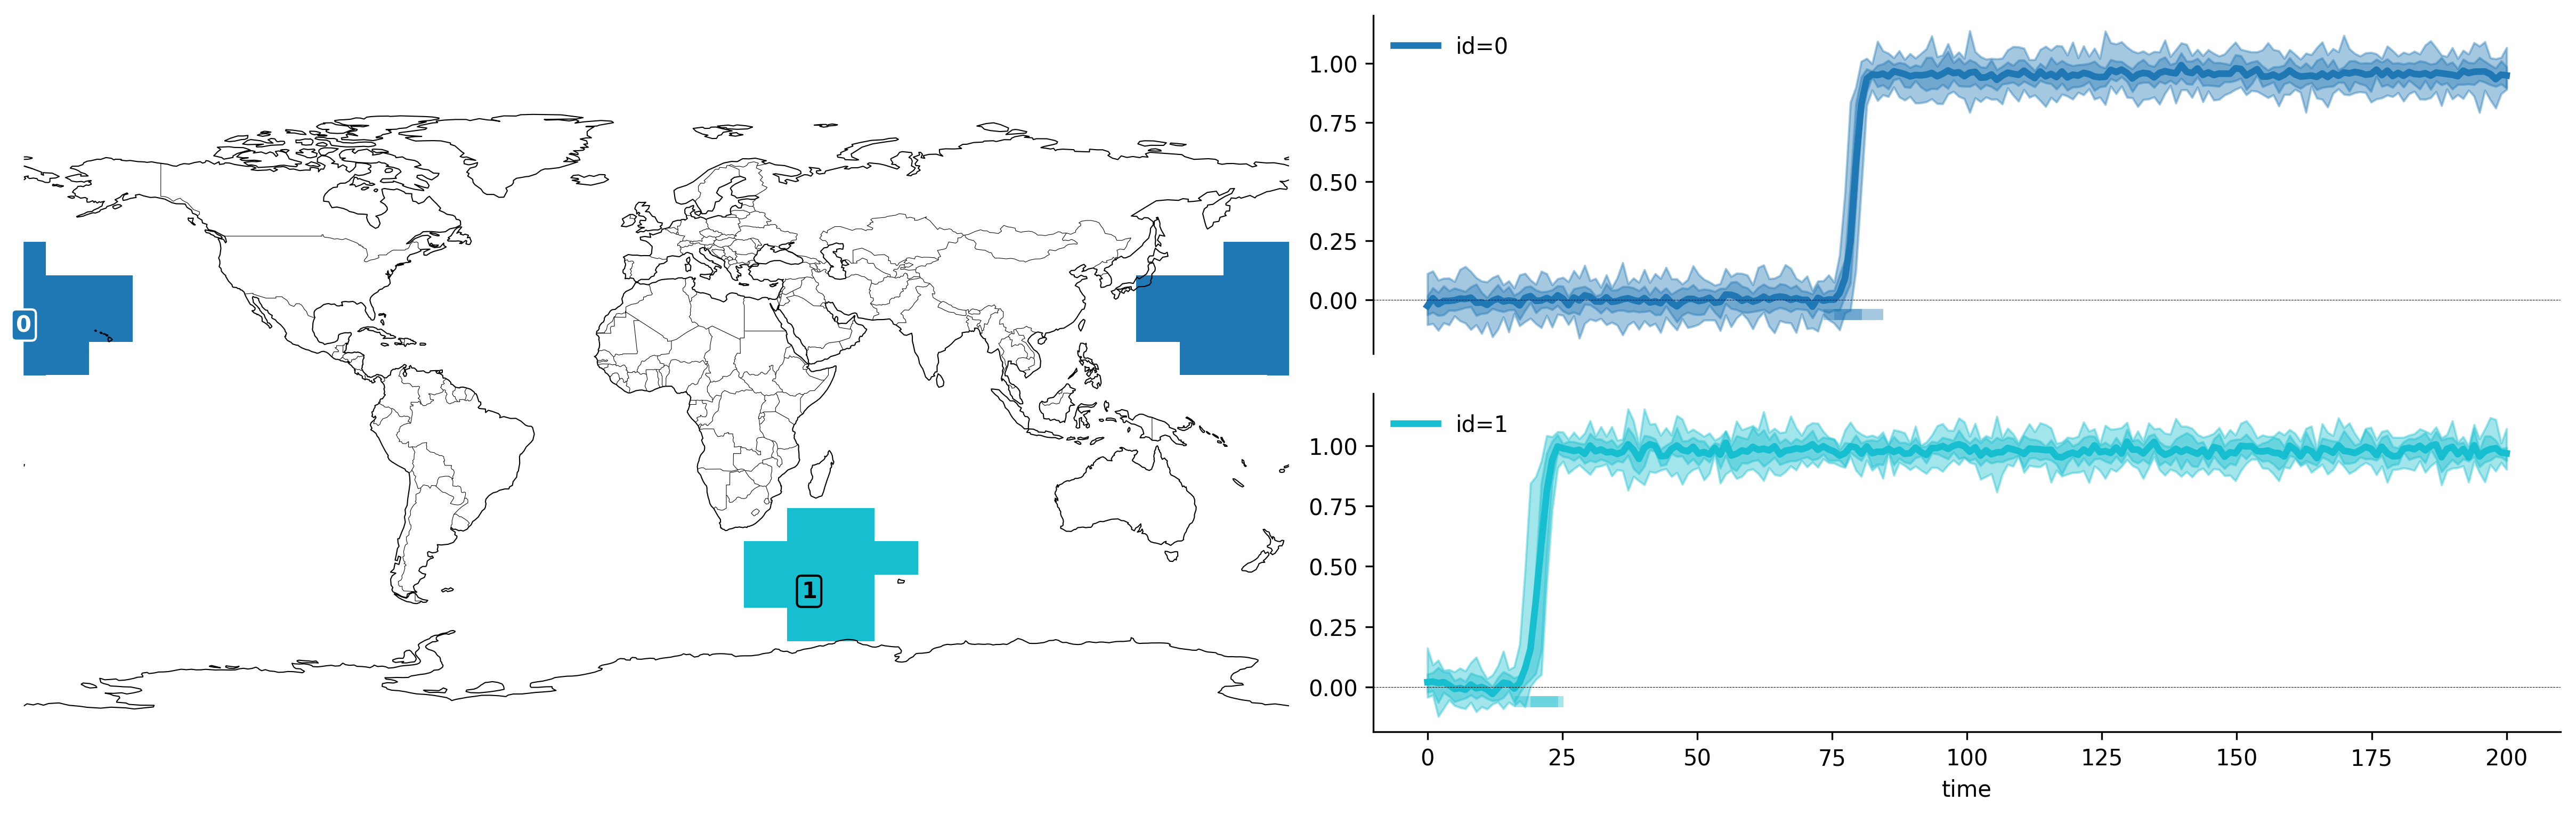

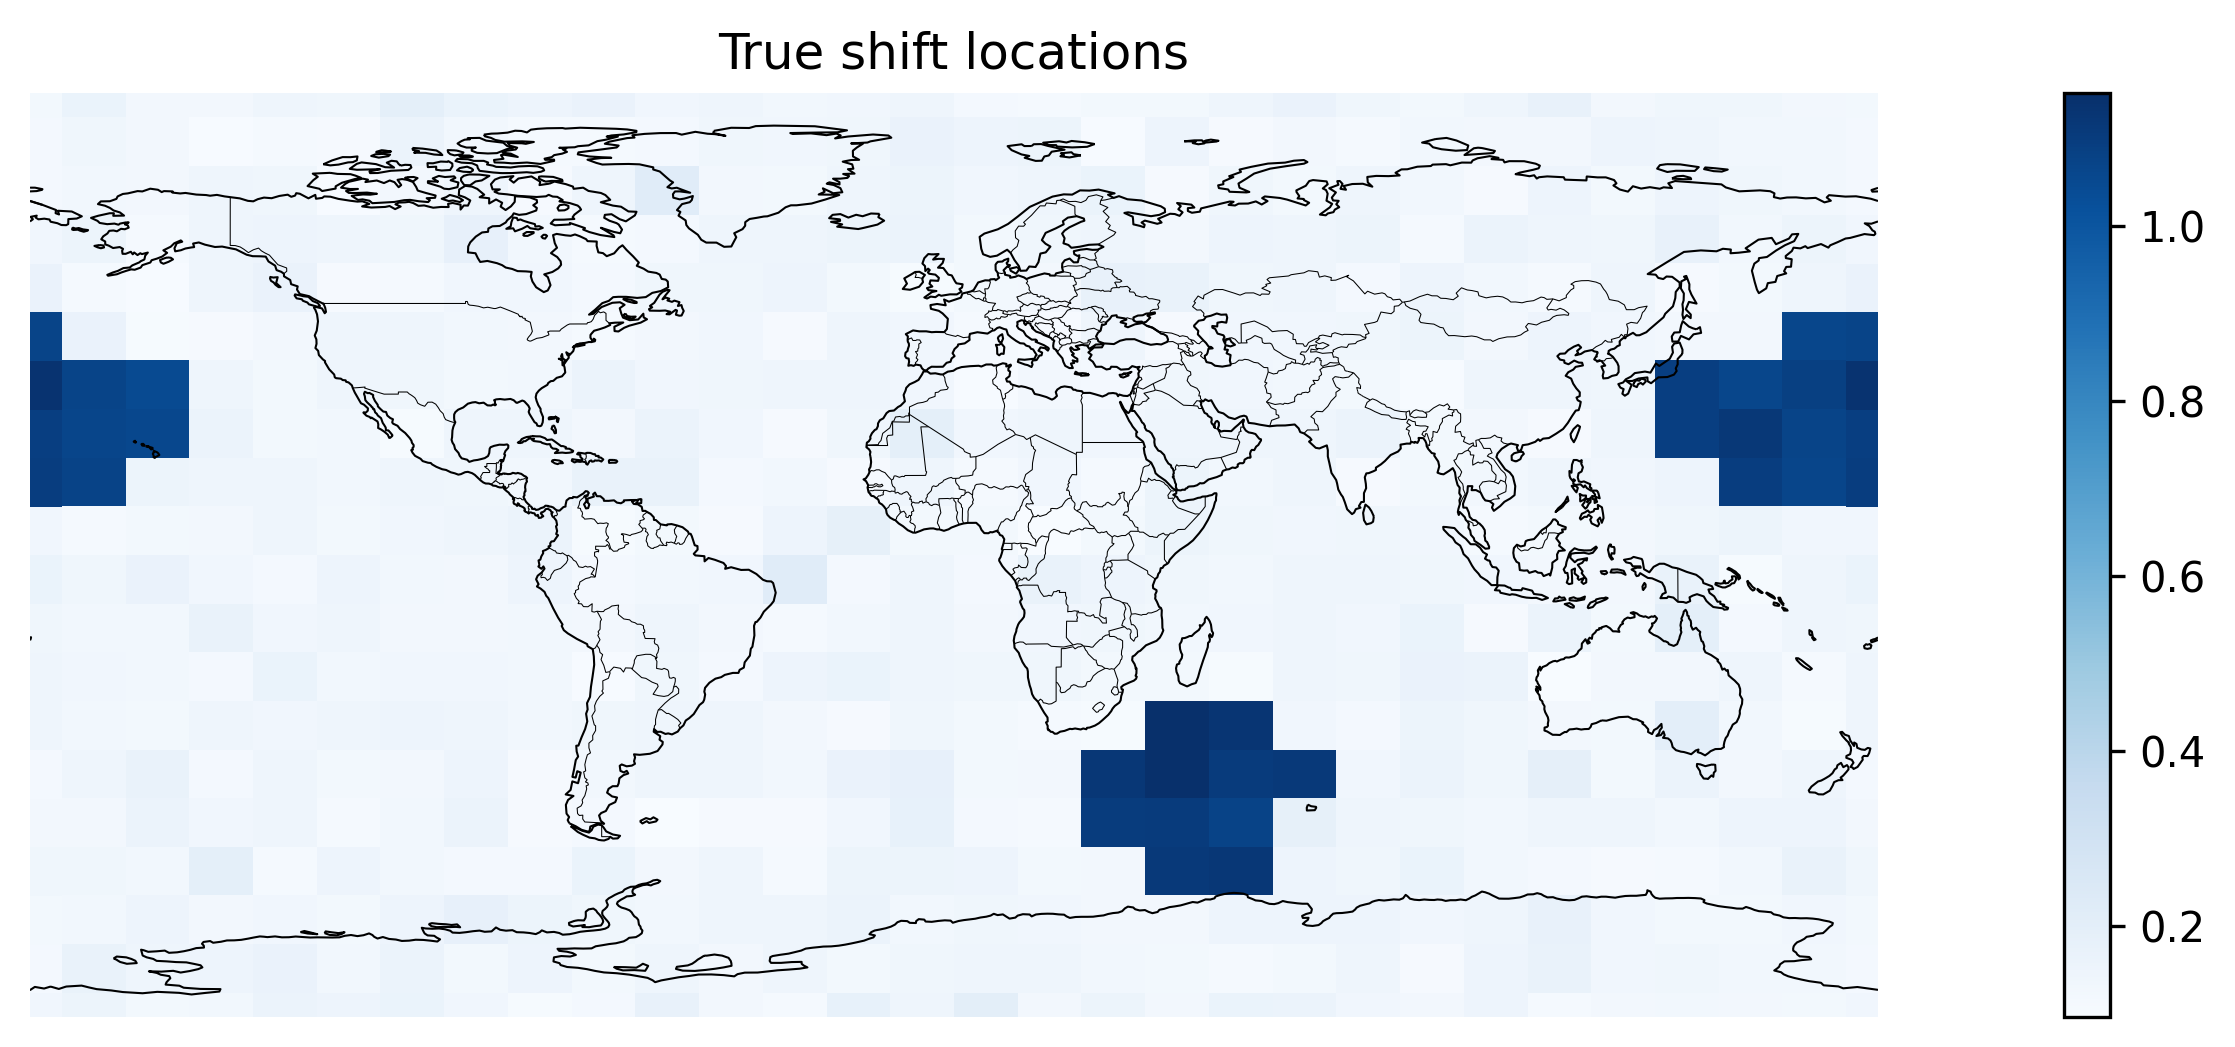

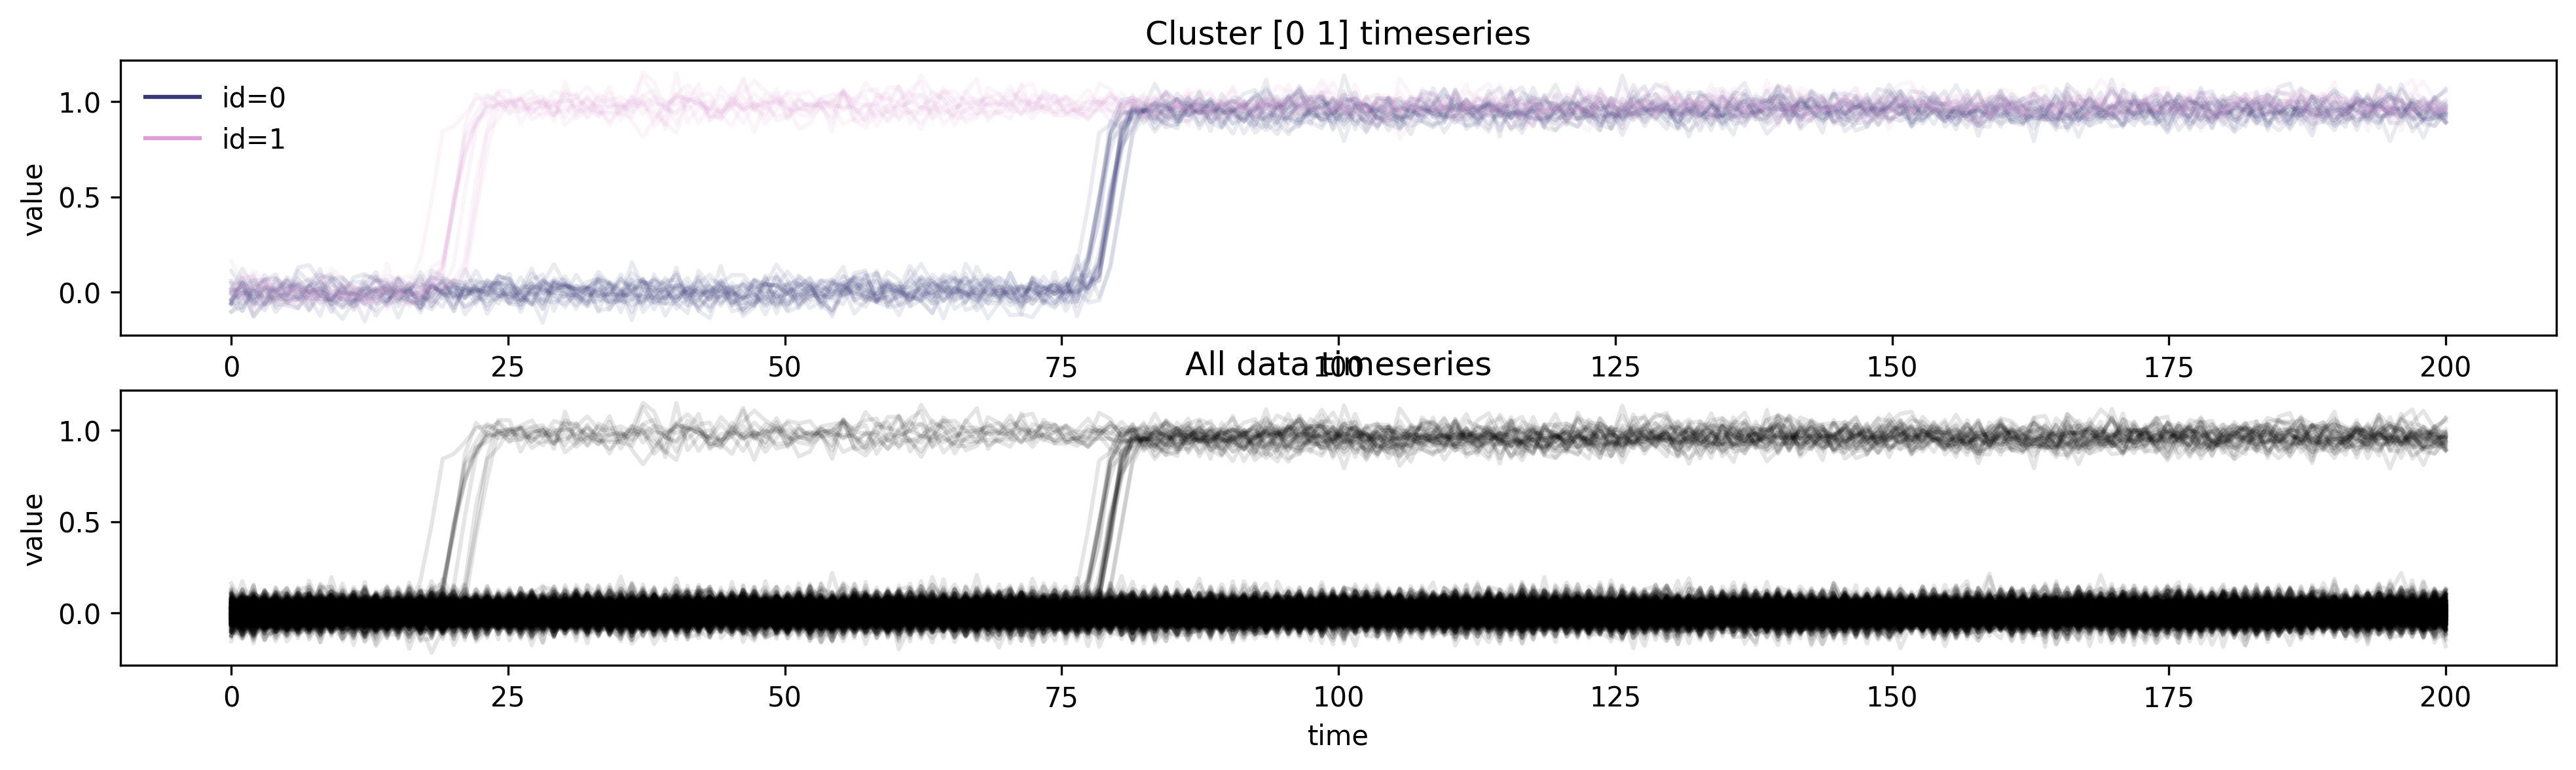

In [29]:
plot(random_seed=2, n_shifts=2)

## Creating a Single Time Series

Another advantage of `PONDS` is that it can also be used to generate single time series. For that matter, we use the `shape_method = SINGLE`. This method is a little special compare to the other shape methods. When calling it **for the first time** with a given PONDS object that is not of the shape `(lat_size x lon_size) = (1 x 1)`, it erases all previously generated content in the time series of the class object and generates a new grid, containing only a single time series. This time series can be modified the same way as before by adding abrupt shifts.

In [33]:
from ponds import PONDS, SINGLE, SIGMOID
import matplotlib.pyplot as plt

In [34]:
pd = PONDS(time_size=200, background_noise=0.01, background_trend=0.002)


pd.add_shift(random_seed=1, shape_method=SINGLE, shift_method=SIGMOID)

shift_dict = {"shift_magnitude": -1}
pd.add_shift(
    random_seed=2,
    shape_method=SINGLE,
    shift_method=SIGMOID,
    kwargs=shift_dict,
)

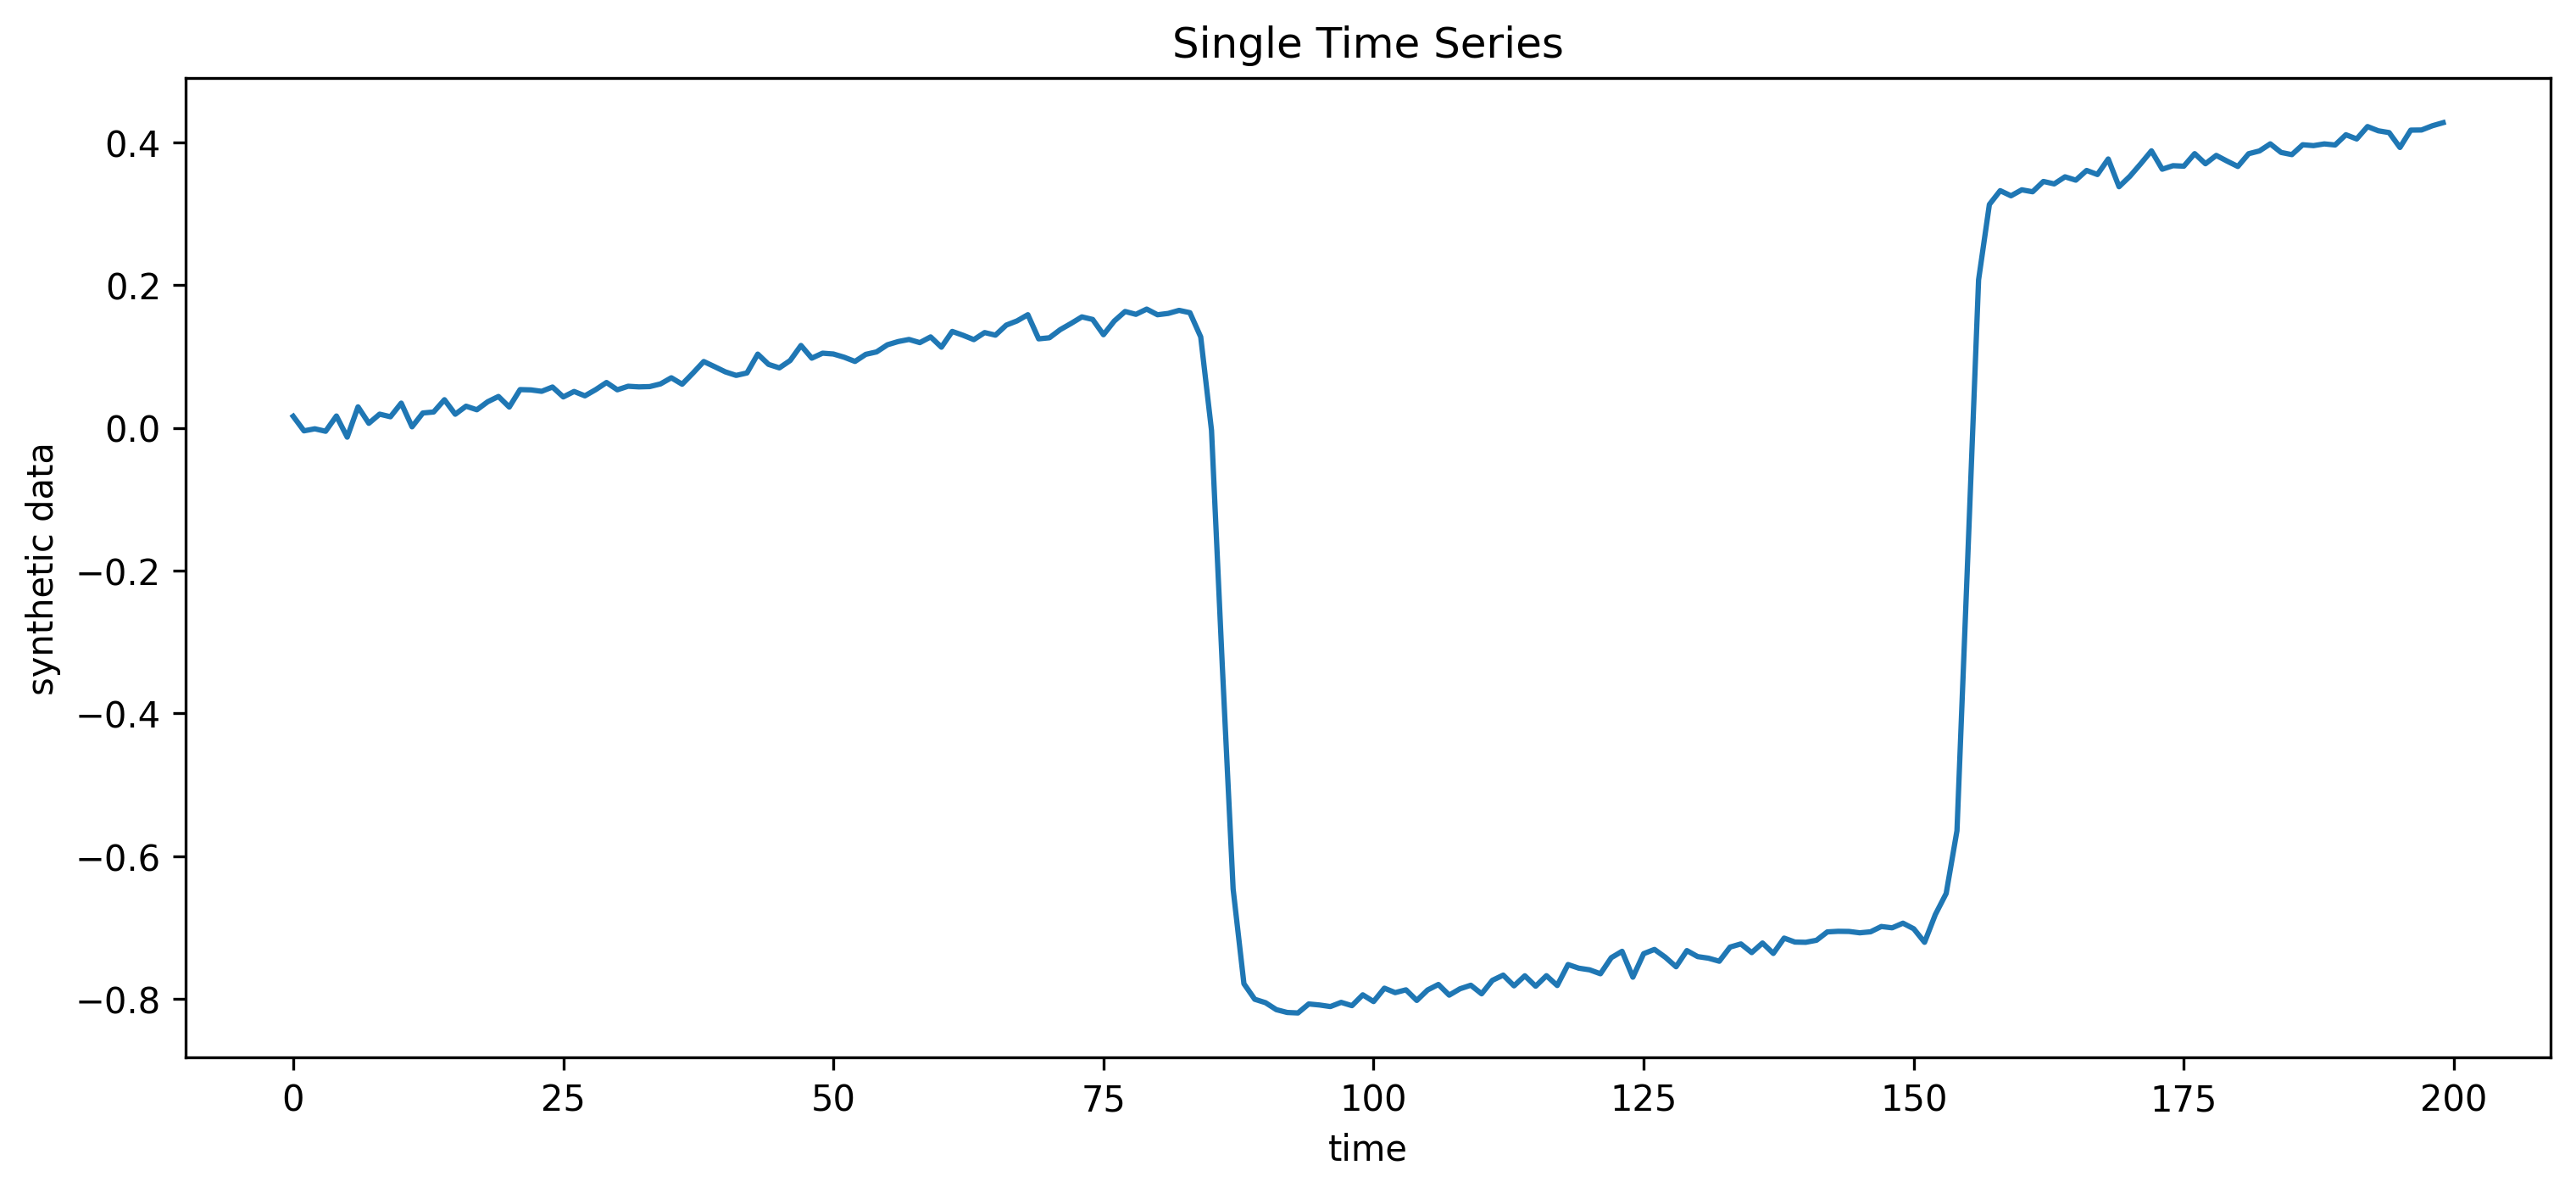

In [35]:
ts = pd.get_ts(single=True)


plt.plot(ts)

plt.title("Single Time Series")
plt.xlabel("time")
plt.ylabel("synthetic data")
plt.show()